In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import warnings

In [ ]:
# setup display
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.max_row', 90)

In [ ]:
%load_ext cache_magic

## Data

### RNN

In [ ]:
rnn_data = pd.read_csv("ensemble_data/RNNClassifier-1.000/metrics.csv")

In [ ]:
rnn_data

### Tranformer

In [ ]:
trans_data = pd.read_csv("ensemble_data/DDoSTransformer-1.000/metrics.csv")

In [ ]:
trans_data

### LSTM

In [ ]:
lstm_data = pd.read_csv("ensemble_data/LSTMNetwork-1.000/metrics.csv")

In [ ]:
lstm_data

### Pretrain DBN

In [ ]:
pre_dbn_data = pd.read_csv("data/history_DBNNetwork/DBNNetwork_pretrain_finetune_Run(hidden_dims=[64, 32], dropout=0.2, reconstruction_weight=0.1, pretrain_epochs=5, finetune_epochs=15, pretrain_lr=0.001, finetune_lr=0.001, use_batch_norm=True).csv")

In [ ]:
pre_dbn_data

In [ ]:
pre_dbn_data.columns

In [ ]:
pdbn_c = [
'epoch', 'phase', 'epoch_duration', 'run_duration', 'train_loss',
'train_accuracy', 'val_loss', 'val_accuracy',
'hidden_dims', 'dropout',
'finetune_lr', 'use_batch_norm',
'train_cohen_kappa', 'train_f1_score', 'train_precision',
'train_recall', 'train_sensitivity', 'train_specificity',
'val_cohen_kappa', 'val_f1_score', 'val_precision', 'val_recall',
'val_sensitivity', 'val_specificity','class_loss'
]
predbn = pre_dbn_data[pdbn_c]
predbn

### DBN

In [ ]:
dbn_data = pd.read_csv("ensemble_data/DBNNetwork-1.000/metrics.csv")

In [ ]:
dbn_data

### Autonecoder

In [ ]:
autoencoder_data =  pd.read_csv("ensemble_data/TimeSeriesAutoEncoder-1.000/metrics.csv")

In [ ]:
autoencoder_data

### Ensembles

### DBNNetwork-0.150_DDoSTransformer-0.450_LSTMNetwork-0.100_RNNClassifier-0.050_TimeSeriesAutoEncoder-0.250

In [ ]:
auto_dbn_lstm_rnn_trans_25_15_10_5_45 =  pd.read_csv("ensemble_data/DBNNetwork-0.150_DDoSTransformer-0.450_LSTMNetwork-0.100_RNNClassifier-0.050_TimeSeriesAutoEncoder-0.250/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_25_15_10_5_45

### DBNNetwork-0.167_DDoSTransformer-0.333_LSTMNetwork-0.167_RNNClassifier-0.083_TimeSeriesAutoEncoder-0.250

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33 =  pd.read_csv("ensemble_data/DBNNetwork-0.167_DDoSTransformer-0.333_LSTMNetwork-0.167_RNNClassifier-0.083_TimeSeriesAutoEncoder-0.250/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33

### cyberspace/ensemble_data/DBNNetwork-0.200_DDoSTransformer-0.200_LSTMNetwork-0.200_RNNClassifier-0.200_TimeSeriesAutoEncoder-0.200

In [ ]:
auto_dbn_lstm_rnn_trans_20_20_20_20_20 =  pd.read_csv("ensemble_data/DBNNetwork-0.200_DDoSTransformer-0.200_LSTMNetwork-0.200_RNNClassifier-0.200_TimeSeriesAutoEncoder-0.200/metrics.csv")

In [ ]:
auto_dbn_lstm_rnn_trans_20_20_20_20_20

In [ ]:
Model_data = [rnn_data, trans_data, predbn, lstm_data, dbn_data, autoencoder_data,auto_dbn_lstm_rnn__trans_25_15_10_5_45,auto_dbn_lstm_rnn__trans_25_16_16_8_33,auto_dbn_lstm_rnn__trans_20_20_20_20_20]

## Plots

In [ ]:
new_colors = {
    'Transformer': 'mediumseagreen',
    'RNN': 'cadetblue',
    'pretrained DBN': 'cornflowerblue',
    'DBN': 'darkorchid',
    'LSTM': 'teal',
    "Autocoder": 'lightcoral',
    "ADLRT_20_20_20_20_20": 'mistyrose',
    "ADLRT_25_16_16_8_33": 'dodgerblue',
    "ADLRT_25_15_10_5_45": 'bisque'
}

In [ ]:
auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1]

### model accuracy compare

In [ ]:
%%cache ensemble_accuracycomp --show

# Final accuracy dictionary (replace with actual last values)

model_accuracies = {
    'Transformer': trans_data["accuracy"][:1].iloc[-1],
    'RNN': rnn_data["accuracy"][:1].iloc[-1],
    'pretrained DBN': predbn["val_accuracy"][1:11].iloc[-1],
    'DBN': dbn_data["accuracy"][:1].iloc[-1],
    'LSTM': lstm_data["accuracy"][:1].iloc[-1],
    'Autocoder': autoencoder_data["accuracy"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["accuracy"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["accuracy"][:1].iloc[-1]
}

# Sort models by accuracy
sorted_models = sorted(model_accuracies.items(), key=lambda x: x[1], reverse=True)
labels = [name for name,_ in sorted_models]
scores = [acc for _, acc in sorted_models]
colors = [new_colors.get(name, 'gray') for name in labels]
# Plot
fig, ax = plt.subplots(figsize=(6, 6))
bars = ax.bar(labels, scores, color=colors, edgecolor='black')

# Add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.4f}',
            ha='center', va='bottom', fontsize=10)

# Styling
ax.set_title('Model Accuracy Comparison')
ax.set_ylabel('Accuracy')
#ax.set_ylim(0, 1.0)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.xticks(rotation=60, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

### All metrics compare

In [ ]:

%%cache ensemble_modelallmetricscomp --show

metrics = {
    'Accuracy': {
    'Transformer': trans_data["accuracy"][:1].iloc[-1],
    'RNN': rnn_data["accuracy"][:1].iloc[-1],
    'pretrained DBN': predbn["val_accuracy"][1:11].iloc[-1],
    'DBN': dbn_data["accuracy"][:1].iloc[-1],
    'LSTM': lstm_data["accuracy"][:1].iloc[-1],
    'Autocoder': autoencoder_data["accuracy"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["accuracy"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["accuracy"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["accuracy"][:1].iloc[-1]
    },
    'Precision': {
    'Transformer': trans_data["precision"][:1].iloc[-1],
    'RNN': rnn_data["precision"][:1].iloc[-1],
    'pretrained DBN': predbn["val_precision"][1:11].iloc[-1],
    'DBN': dbn_data["precision"][:1].iloc[-1],
    'LSTM': lstm_data["precision"][:1].iloc[-1],
    'Autocoder': autoencoder_data["precision"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["precision"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["precision"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["precision"][:1].iloc[-1]
    },
    'Recall': {
    'Transformer': trans_data["recall"][:1].iloc[-1],
    'RNN': rnn_data["recall"][:1].iloc[-1],
    'pretrained DBN': predbn["val_recall"][1:11].iloc[-1],
    'DBN': dbn_data["recall"][:1].iloc[-1],
    'LSTM': lstm_data["recall"][:1].iloc[-1],
    'Autocoder': autoencoder_data["recall"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["recall"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["recall"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["recall"][:1].iloc[-1]
    },
    'Specificity': {
    'Transformer': trans_data["specificity"][:1].iloc[-1],
    'RNN': rnn_data["specificity"][:1].iloc[-1],
    'pretrained DBN': predbn["val_specificity"][1:11].iloc[-1],
    'DBN': dbn_data["specificity"][:1].iloc[-1],
    'LSTM': lstm_data["specificity"][:1].iloc[-1],
    'Autocoder': autoencoder_data["specificity"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["specificity"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["specificity"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["specificity"][:1].iloc[-1]

    }
}

# Setup
metric_names = list(metrics.keys())
model_names = list(new_colors.keys())
n_metrics = len(metric_names)
n_models = len(model_names)
bar_width = 0.13
group_spacing = 0.3

# Compute positions
indices = np.arange(n_metrics) * (n_models * bar_width + group_spacing)

fig, ax = plt.subplots(figsize=(15, 20))

# Plot each model's bars, offset within the group
for i, model in enumerate(model_names):
    values = [metrics[metric].get(model, 0) for metric in metric_names]
    positions = indices + i * bar_width
    color = new_colors[model]
    bars = ax.bar(positions, values, width=bar_width, label=model, color=color, edgecolor='black')

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.3f}',
                ha='center', va='bottom', fontsize=6)

# Label setup
ax.set_title('Model Performance Metrics Comparison')
ax.set_ylabel('Score')
#ax.set_ylim(0, 1.0)

# Set x-ticks to be centered under each group
group_centers = indices + (n_models / 2 - 0.5) * bar_width
ax.set_xticks(group_centers)
ax.set_xticklabels(metric_names)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.10), ncol=len(model_names), frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
%%cache ensemble_modelkapf1metricscomp --show

f1_k_metrics = {
    'F1 Score': {
    'Transformer': trans_data["f1_score"][:1].iloc[-1],
    'RNN': rnn_data["f1_score"][:1].iloc[-1],
    'pretrained DBN': predbn["val_f1_score"][1:11].iloc[-1],
    'DBN': dbn_data["f1_score"][:1].iloc[-1],
    'LSTM': lstm_data["f1_score"][:1].iloc[-1],
    'Autocoder': autoencoder_data["f1_score"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["f1_score"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["f1_score"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["f1_score"][:1].iloc[-1]
    },
    'Cohen Kappa Score': {
    'Transformer': trans_data["cohen_kappa"][:1].iloc[-1],
    'RNN': rnn_data["cohen_kappa"][:1].iloc[-1],
    'pretrained DBN': predbn["val_cohen_kappa"][1:11].iloc[-1],
    'DBN': dbn_data["cohen_kappa"][:1].iloc[-1],
    'LSTM': lstm_data["cohen_kappa"][:1].iloc[-1],
    'Autocoder': autoencoder_data["cohen_kappa"][:1].iloc[-1],
    "ADLRT_20_20_20_20_20": auto_dbn_lstm_rnn_trans_20_20_20_20_20["cohen_kappa"][:1].iloc[-1],
    "ADLRT_25_16_16_8_33": auto_dbn_lstm_rnn_trans_25_16_16_8_33["cohen_kappa"][:1].iloc[-1],
    "ADLRT_25_15_10_5_45": auto_dbn_lstm_rnn_trans_25_15_10_5_45["cohen_kappa"][:1].iloc[-1]

    }
}

# Setup
metric_names = list(f1_k_metrics.keys())
model_names = list(new_colors.keys())
n_metrics = len(metric_names)
n_models = len(model_names)
bar_width = 0.13
group_spacing = 0.3

# Compute positions
indices = np.arange(n_metrics) * (n_models * bar_width + group_spacing)

fig, ax = plt.subplots(figsize=(15, 6))

# Plot each model's bars, offset within the group
for i, model in enumerate(model_names):
    values = [f1_k_metrics[metric].get(model, 0) for metric in metric_names]
    positions = indices + i * bar_width
    color = new_colors[model]
    bars = ax.bar(positions, values, width=bar_width, label=model, color=color, edgecolor='black')

    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.4f}',
                ha='center', va='bottom', fontsize=6)

# Label setup
ax.set_title('Model Performance Metrics Comparison')
ax.set_ylabel('Score')
#ax.set_ylim(0, 1.0)

# Set x-ticks to be centered under each group
group_centers = indices + (n_models / 2 - 0.5) * bar_width
ax.set_xticks(group_centers)
ax.set_xticklabels(metric_names)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.10), ncol=len(model_names), frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

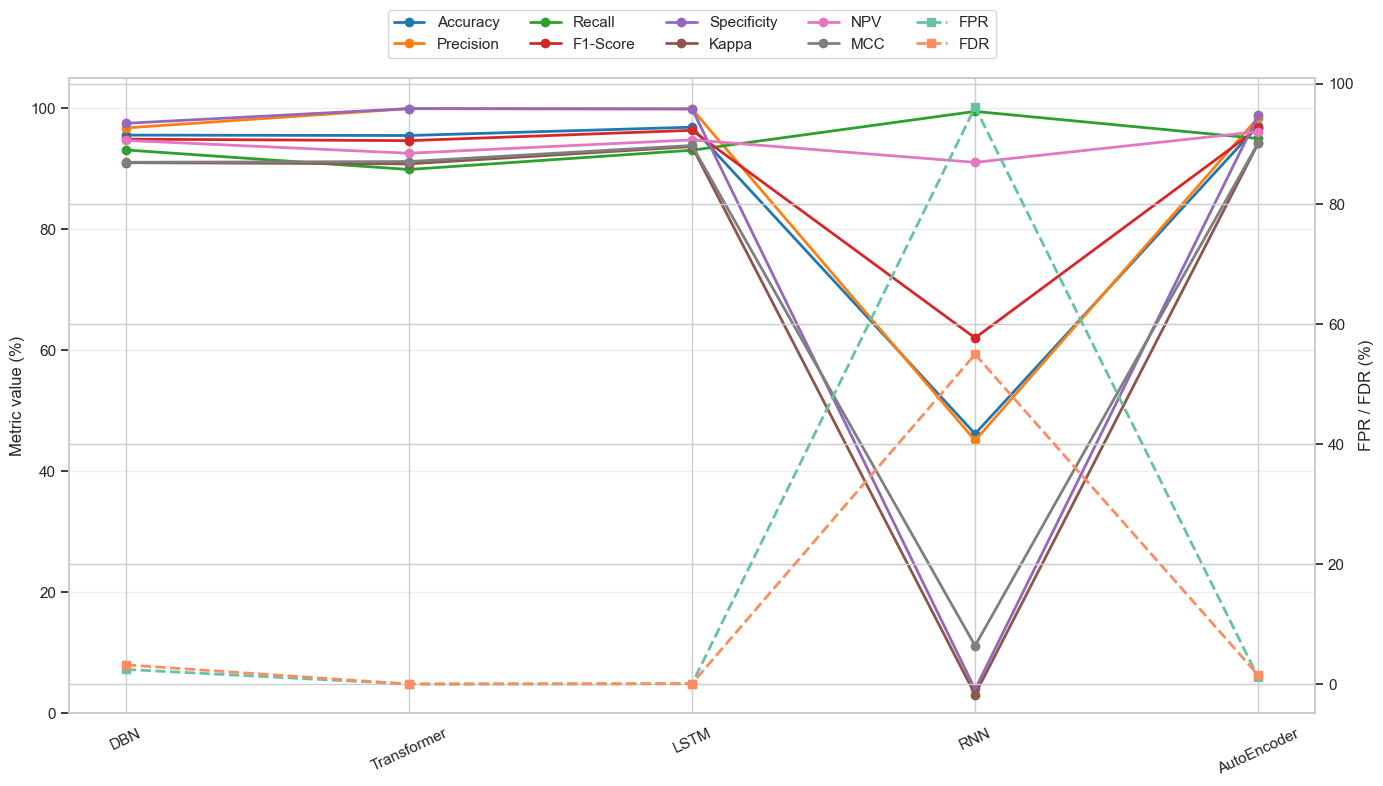

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data transcribed from the image table
data = {
    "Model": ["DBN", "Transformer", "LSTM", "RNN", "AutoEncoder"],

    "Accuracy": [95.60, 95.53, 96.91, 46.17, 97.17],
    "Precision": [96.79, 99.98, 99.92, 45.07, 98.50],
    "Recall": [93.14, 89.91, 93.10, 99.52, 95.04],
    "F1-Score": [94.93, 94.68, 96.39, 62.04, 96.74],

    "Specificity": [97.55, 99.98, 99.94, 3.90, 98.85],
    "Kappa": [91.04, 90.84, 93.70, 3.04, 94.23],
    "NPV": [94.72, 92.60, 94.81, 91.09, 96.18],
    "MCC": [91.10, 91.22, 93.88, 11.11, 94.28],

    # FPR and FDR remain in decimal form (as in the table)
    "FPR": [0.0245, 0.0002, 0.0006, 0.9610, 0.0115],
    "FDR": [0.0321, 0.0002, 0.0009, 0.5493, 0.0150],
}


df = pd.DataFrame(data).set_index("Model")

# Convert FPR/FDR to percent so axis label is intuitive (0.0017 -> 0.17%)
df["FPR_pct"] = df["FPR"] * 100
df["FDR_pct"] = df["FDR"] * 100

# Metrics to show on the primary axis (0-100 scale)
main_metrics = ["Accuracy", "Precision", "Recall",
                "F1-Score", "Specificity", "Kappa", "NPV", "MCC"]
# Small metrics to show on the secondary axis (percent, small numbers)
small_metrics = ["FPR_pct", "FDR_pct"]

sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 8))

# Plot main metrics on primary y-axis
colors = sns.color_palette("tab10", n_colors=len(main_metrics))
for col, c in zip(main_metrics, colors):
    ax.plot(df.index, df[col], marker="o", linewidth=2, label=col, color=c)

ax.set_ylabel("Metric value (%)", fontsize=12)
ax.set_ylim(0, 105)
# ax.set_title(
#     "Model performance metrics (all on a single plot with secondary axis for tiny rates)", fontsize=14)

# Secondary y-axis for FPR and FDR (percent)
ax2 = ax.twinx()
colors2 = sns.color_palette("Set2", n_colors=len(small_metrics))
for col, c in zip(small_metrics, colors2):
    # Use dashed lines for the small metrics so they visually differ
    ax2.plot(df.index, df[col], marker="s", linewidth=2,
             linestyle="--", label=col.replace("_pct", ""), color=c)

ax2.set_ylabel("FPR / FDR (%)", fontsize=12)

# Combine legends from both axes into one
handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
all_handles = handles1 + handles2
all_labels = labels1 + labels2
ax.legend(all_handles, all_labels, loc="upper center",
          bbox_to_anchor=(0.5, 1.12), ncol=5)

# Improve layout & ticks
ax.set_xticks(range(len(df.index)))
ax.set_xticklabels(df.index, rotation=25)
ax.grid(True, axis="y", alpha=0.35)

plt.tight_layout()
plt.savefig("model_metrics_single_plot.png", dpi=200)
plt.show()

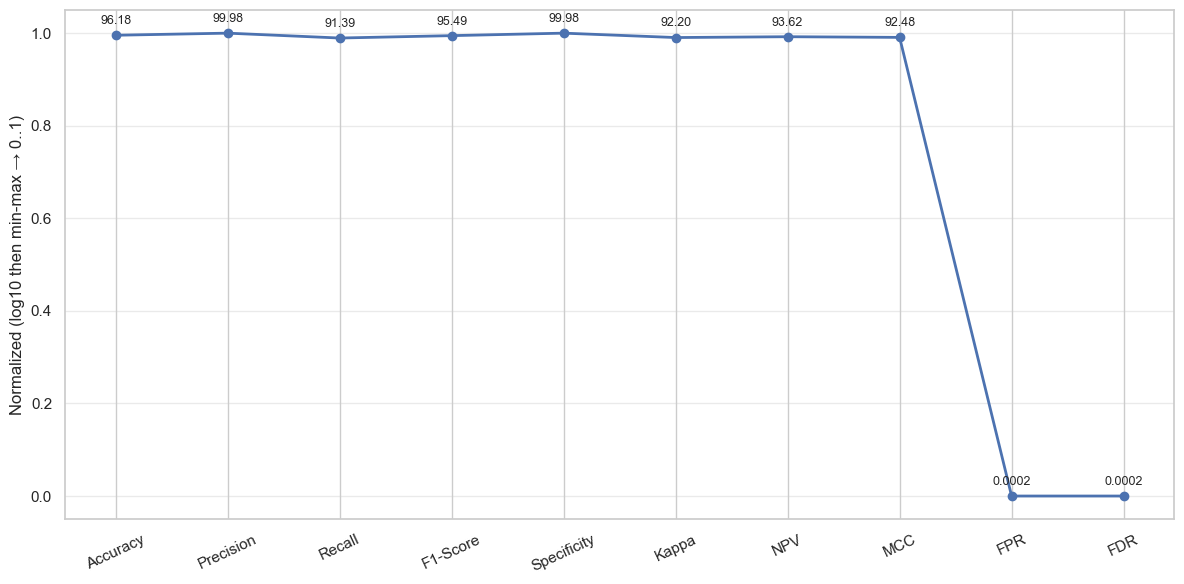

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data transcribed from Image 2 (single-row table)
# Note: FPR and FDR in the image are very small (e.g. 0.0003), treated here as decimals.
data = {
    "Accuracy": 96.18,
    "Precision": 99.98,
    "Recall": 91.39,
    "F1-Score": 95.49,
    "Specificity": 99.98,
    "Kappa": 92.20,
    "NPV": 93.62,
    "MCC": 92.48,
    "FPR": 0.0002,   # decimal in table
    "FDR": 0.0002,   # decimal in table
}

# Order in which to plot the metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "Specificity",
           "Kappa", "NPV", "MCC", "FPR", "FDR"]

# For normalization we must compare values on the same unit.
# Convert FPR/FDR from decimals to percent so units match the other metrics (which are already percents).
display_values = []
raw_values = []  # keep original raw numbers for annotation
for m in metrics:
    v = data[m]
    raw_values.append(v)
    if m in ("FPR", "FDR"):
        # convert to percent for scaling/visualization (0.0003 -> 0.03)
        display_values.append(v * 100.0)
    else:
        display_values.append(v)

# To make small rates visible on the same single plot we:
# 1) take log10 of each display value (all positive)
# 2) min-max scale the log10 values to [0,1]
vals = np.array(display_values, dtype=float)
# Guard against any non-positive values (shouldn't happen here)
if np.any(vals <= 0):
    raise ValueError("All metric values must be positive for log transform.")

log_vals = np.log10(vals)
log_min, log_max = log_vals.min(), log_vals.max()
if np.isclose(log_max, log_min):
    norm = np.full_like(log_vals, 0.5)
else:
    norm = (log_vals - log_min) / (log_max - log_min)

# Plot
sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(metrics))
ax.plot(x, norm, marker="o", linewidth=2, color="pink")

# Annotate each point with the original value (formatted nicely).
for xi, m, raw_v in zip(x, metrics, raw_values):
    if m in ("FPR", "FDR"):
        # Show the tiny rates in their original decimal form (as in the table)
        label = f"{raw_v:.4f}"
    else:
        # Main metrics are percentages
        label = f"{raw_v:.2f}"
    ax.annotate(label, (xi, norm[xi]),
                textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)

# Improve appearance
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=25)
ax.set_ylabel("Normalized (log10 then min-max → 0..1)")
# ax.set_title(
    # "All metrics on a single plot (log-scaled then normalized), with original values annotated")
ax.set_ylim(-0.05, 1.05)
ax.grid(True, axis="y", alpha=0.4)

plt.tight_layout()
plt.savefig("all_metrics_single_plot_normalized.png", dpi=200)
plt.show()

Mitigation

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data from your table
strategies = ["Block", "Rate-limit"]
thresholds = [0.7, 0.5]  # values in 0..1

# Choose color (change here)
BAR_COLOR = "#2b8cbe"

# Optionally display as percent:
thresholds_pct = [t * 100 for t in thresholds]

sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 3.5))

y_pos = range(len(strategies))
ax.barh(y_pos, thresholds_pct, color=BAR_COLOR, height=0.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(strategies)
ax.set_xlim(0, 100)
ax.set_xlabel("Threshold (%)")
# ax.set_title("Mitigation strategy thresholds")

# annotate values on bars
for i, v in enumerate(thresholds_pct):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=10)

plt.tight_layout()
plt.show()

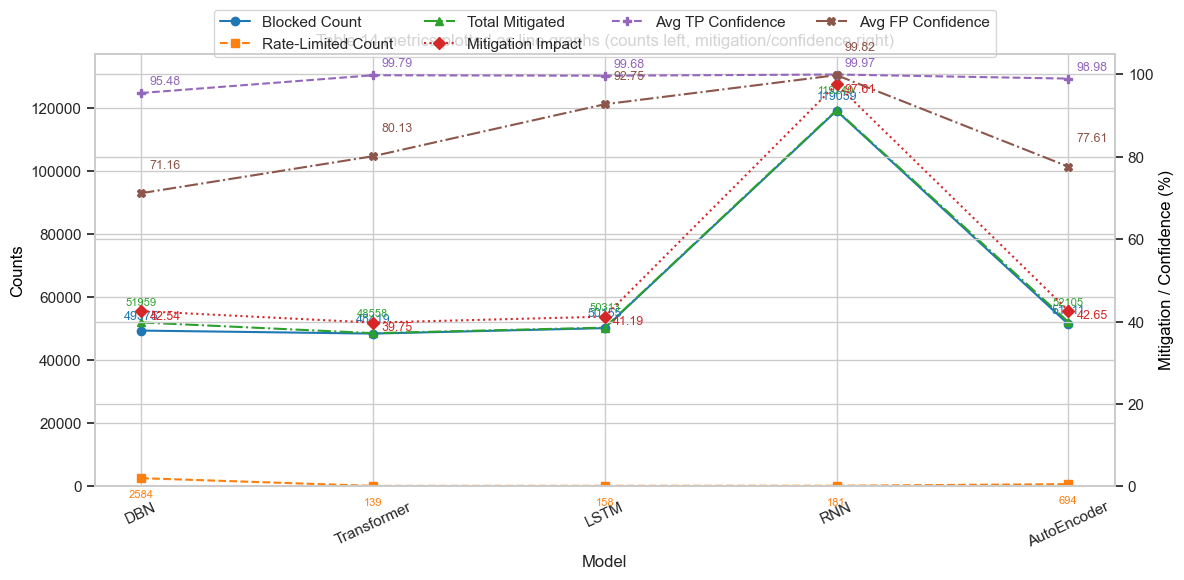

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Data transcribed from Image 4 (Table 14)
data = {
    "Model": ["DBN", "Transformer", "LSTM", "RNN", "AutoEncoder"],
    "Blocked Count": [49375, 48419, 50155, 119059, 51411],
    "Rate-Limited Count": [2584, 139, 158, 181, 694],
    "Total Mitigated": [51959, 48558, 50313, 119240, 52105],
    "Mitigation Impact": [42.54, 39.75, 41.19, 97.61, 42.65],
    "Avg TP Confidence": [95.48, 99.79, 99.68, 99.97, 98.98],
    "Avg FP Confidence": [71.16, 80.13, 92.75, 99.82, 77.61],
}

df = pd.DataFrame(data).set_index("Model")

# --- Color settings (change these if you want different colors) ---
# for Blocked, Rate-Limited, Total (left axis)
COUNT_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c"]
# for Mitigation Impact, Avg TP Conf, Avg FP Conf (right axis)
IMPACT_CONF_COLORS = ["#d62728", "#9467bd", "#8c564b"]
# -----------------------------------------------------------------

sns.set(style="whitegrid")
fig, ax_counts = plt.subplots(figsize=(12, 6))

models = df.index.tolist()
x = np.arange(len(models))

# Plot counts on the left y-axis (linear scale)
ax_counts.plot(x, df["Blocked Count"], marker="o",
               linestyle="-", color=COUNT_COLORS[0], label="Blocked Count")
ax_counts.plot(x, df["Rate-Limited Count"], marker="s",
               linestyle="--", color=COUNT_COLORS[1], label="Rate-Limited Count")
ax_counts.plot(x, df["Total Mitigated"], marker="^",
               linestyle="-.", color=COUNT_COLORS[2], label="Total Mitigated")
ax_counts.set_ylabel("Counts", color="black")
ax_counts.set_ylim(
    0, max(df[["Blocked Count", "Total Mitigated"]].max()) * 1.15)

# Annotate counts
for i, model in enumerate(models):
    ax_counts.annotate(f"{int(df.loc[model, 'Blocked Count'])}", (i, df.loc[model, 'Blocked Count']),
                       textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=COUNT_COLORS[0])
    ax_counts.annotate(f"{int(df.loc[model, 'Rate-Limited Count'])}", (i, df.loc[model, 'Rate-Limited Count']),
                       textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color=COUNT_COLORS[1])
    ax_counts.annotate(f"{int(df.loc[model, 'Total Mitigated'])}", (i, df.loc[model, 'Total Mitigated']),
                       textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8, color=COUNT_COLORS[2])

# Secondary axis for Mitigation Impact and confidences (percent-like metrics)
ax_metrics = ax_counts.twinx()
ax_metrics.plot(x, df["Mitigation Impact"], marker="D", linestyle=":",
                color=IMPACT_CONF_COLORS[0], label="Mitigation Impact")
ax_metrics.plot(x, df["Avg TP Confidence"], marker="P", linestyle="--",
                color=IMPACT_CONF_COLORS[1], label="Avg TP Confidence")
ax_metrics.plot(x, df["Avg FP Confidence"], marker="X", linestyle="-.",
                color=IMPACT_CONF_COLORS[2], label="Avg FP Confidence")
ax_metrics.set_ylabel("Mitigation / Confidence (%)", color="black")
# set a sensible range for the percent axis
ax_metrics.set_ylim(0, 105)

# Annotate percent-like metrics
for i, model in enumerate(models):
    ax_metrics.annotate(f"{df.loc[model, 'Mitigation Impact']:.2f}", (i, df.loc[model, 'Mitigation Impact']),
                        textcoords="offset points", xytext=(6, -6), ha="left", fontsize=9, color=IMPACT_CONF_COLORS[0])
    ax_metrics.annotate(f"{df.loc[model, 'Avg TP Confidence']:.2f}", (i, df.loc[model, 'Avg TP Confidence']),
                        textcoords="offset points", xytext=(6, 6), ha="left", fontsize=9, color=IMPACT_CONF_COLORS[1])
    ax_metrics.annotate(f"{df.loc[model, 'Avg FP Confidence']:.2f}", (i, df.loc[model, 'Avg FP Confidence']),
                        textcoords="offset points", xytext=(6, 18), ha="left", fontsize=9, color=IMPACT_CONF_COLORS[2])

# Combined legend: gather handles from both axes
handles_counts, labels_counts = ax_counts.get_legend_handles_labels()
handles_metrics, labels_metrics = ax_metrics.get_legend_handles_labels()
all_handles = handles_counts + handles_metrics
all_labels = labels_counts + labels_metrics
ax_counts.legend(all_handles, all_labels, loc="upper center",
                 bbox_to_anchor=(0.5, 1.12), ncol=4)

# X ticks and labels
ax_counts.set_xticks(x)
ax_counts.set_xticklabels(models, rotation=25)
ax_counts.set_xlabel("Model")
ax_counts.set_title(
    "Table 14 metrics plotted as line graphs (counts left, mitigation/confidence right)")

# Improve layout
fig.tight_layout()
plt.savefig("table14_line_graph.png", dpi=220)
plt.show()

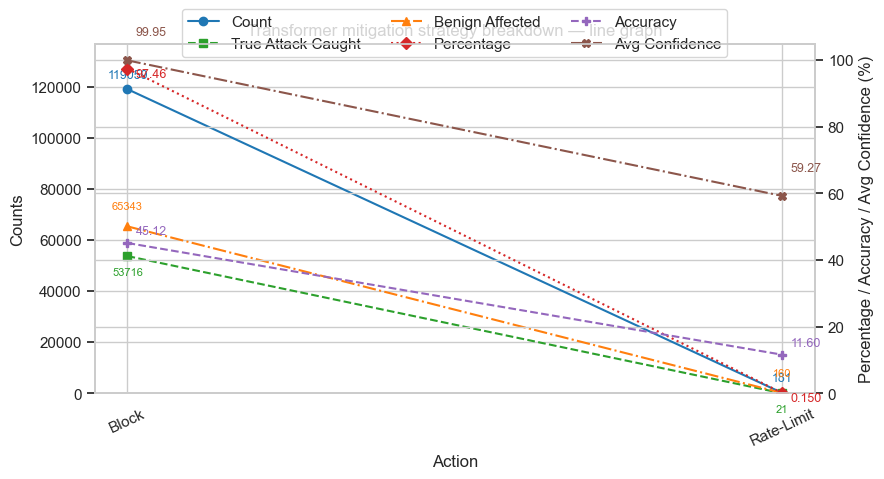

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- Transcribed data from Image 5 (Table 15) ---
data = {
    "Action": ["Block", "Rate-Limit"],
    "Count": [119059, 181],
    "Percentage": [97.46, 0.15],
    "Accuracy": [45.12, 11.60],
    "Avg Confidence": [99.95, 59.27],
    "True Attack Caught": [53716, 21],
    "Benign Affected": [65343, 160],
}

df = pd.DataFrame(data).set_index("Action")

# --- Normalize/clean percent-like columns ---
percent_cols = ["Percentage", "Accuracy", "Avg Confidence"]
# If any percent-like column has max <= 1.01 we assume values are fractions and convert to percent.
for col in percent_cols:
    if df[col].max() <= 1.01:
        df[col] = df[col] * 100.0

# --- Plot settings / colors (change here to customize) ---
# Count, True Attack Caught, Benign Affected
COUNT_COLORS = ["#1f77b4", "#2ca02c", "#ff7f0e"]
# Percentage, Accuracy, Avg Confidence
PERCENT_COLORS = ["#d62728", "#9467bd", "#8c564b"]

sns.set(style="whitegrid")
fig, ax_counts = plt.subplots(figsize=(9, 5))

actions = df.index.tolist()
x = np.arange(len(actions))

# --- Plot counts on left y-axis ---
ax_counts.plot(x, df["Count"], marker="o", linestyle="-",
               color=COUNT_COLORS[0], label="Count")
ax_counts.plot(x, df["True Attack Caught"], marker="s",
               linestyle="--", color=COUNT_COLORS[1], label="True Attack Caught")
ax_counts.plot(x, df["Benign Affected"], marker="^",
               linestyle="-.", color=COUNT_COLORS[2], label="Benign Affected")
ax_counts.set_ylabel("Counts")
ax_counts.set_ylim(
    0, max(df[["Count", "True Attack Caught", "Benign Affected"]].max()) * 1.15)

# Annotate count points
for i, act in enumerate(actions):
    ax_counts.annotate(f"{int(df.loc[act, 'Count'])}", (i, df.loc[act, 'Count']),
                       textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=COUNT_COLORS[0])
    ax_counts.annotate(f"{int(df.loc[act, 'True Attack Caught'])}", (i, df.loc[act, 'True Attack Caught']),
                       textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8, color=COUNT_COLORS[1])
    ax_counts.annotate(f"{int(df.loc[act, 'Benign Affected'])}", (i, df.loc[act, 'Benign Affected']),
                       textcoords="offset points", xytext=(0, 12), ha="center", fontsize=8, color=COUNT_COLORS[2])

# --- Secondary axis for percent-like metrics ---
ax_pct = ax_counts.twinx()
ax_pct.plot(x, df["Percentage"], marker="D", linestyle=":",
            color=PERCENT_COLORS[0], label="Percentage")
ax_pct.plot(x, df["Accuracy"], marker="P", linestyle="--",
            color=PERCENT_COLORS[1], label="Accuracy")
ax_pct.plot(x, df["Avg Confidence"], marker="X", linestyle="-.",
            color=PERCENT_COLORS[2], label="Avg Confidence")
ax_pct.set_ylabel("Percentage / Accuracy / Avg Confidence (%)")
ax_pct.set_ylim(0, max(100, df[percent_cols].max().max()) * 1.05)

# Annotate percent-like points
for i, act in enumerate(actions):
    ax_pct.annotate(f"{df.loc[act, 'Percentage']:.3f}" if df.loc[act, 'Percentage'] < 1 else f"{df.loc[act, 'Percentage']:.2f}",
                    (i, df.loc[act, 'Percentage']),
                    textcoords="offset points", xytext=(6, -6), ha="left", fontsize=9, color=PERCENT_COLORS[0])
    ax_pct.annotate(f"{df.loc[act, 'Accuracy']:.2f}", (i, df.loc[act, 'Accuracy']),
                    textcoords="offset points", xytext=(6, 6), ha="left", fontsize=9, color=PERCENT_COLORS[1])
    ax_pct.annotate(f"{df.loc[act, 'Avg Confidence']:.2f}", (i, df.loc[act, 'Avg Confidence']),
                    textcoords="offset points", xytext=(6, 18), ha="left", fontsize=9, color=PERCENT_COLORS[2])

# --- Legend: combine handles from both axes ---
handles_counts, labels_counts = ax_counts.get_legend_handles_labels()
handles_pct, labels_pct = ax_pct.get_legend_handles_labels()
all_handles = handles_counts + handles_pct
all_labels = labels_counts + labels_pct
ax_counts.legend(all_handles, all_labels, loc="upper center",
                 bbox_to_anchor=(0.5, 1.12), ncol=3)

# --- Final touches ---
ax_counts.set_xticks(x)
ax_counts.set_xticklabels(actions, rotation=25)
ax_counts.set_xlabel("Action")
ax_counts.set_title("Transformer mitigation strategy breakdown — line graph")
fig.tight_layout()
plt.savefig("table15_transformer_strategy_line_graph.png", dpi=220)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# -------------------------
# Data transcribed from Image 11 (Table 28)
# -------------------------
data = {
    "Configuration": [
        "DBN",
        "Transformer",
        "LSTM",
        "RNN",
        "AutoEncoder",
        "Equally Weighted (5 Models)",
        "Transformer Prioritized (5 Models)",
        "Equally Weighted (3 Best)",
        "Transformer Prioritized (3 Best)",
    ],
    "Blocked": [11392, 11344, 11344, 32841, 11373, 11346, 11341, 11341, 11341],
    "Rate-Limited": [19, 1, 1, 803, 7, 9, 5, 6, 6],
    "Total Mitigated": [11411, 11345, 11345, 33344, 11380, 11355, 11346, 11347, 11347],
    "Mitigation Impact (%)": [25.28, 25.13, 25.13, 73.86, 25.21, 25.15, 25.13, 25.13, 25.13],
    "Blocking Accuracy (%)": [99.67, 99.94, 99.94, 34.57, 99.75, 99.96, 99.97, 99.97, 99.97],
    "Avg TP Confidence (%)": [99.97, 99.98, 99.98, 99.95, 99.99, 99.95, 99.97, 99.97, 99.97],
    "Avg FP Confidence (%)": [77.29, 98.74, 90.81, 96.89, 88.21, 71.57, 81.70, 80.53, 79.02],
    "Benign Affected (Blocked)": [37, 7, 7, 21488, 29, 5, 3, 3, 3],
}

df = pd.DataFrame(data).set_index("Configuration")

# -------------------------
# Colors & styles (edit these lists to change colors)
# -------------------------
# for blocked, rate-limited, total, benign
COUNT_COLORS = sns.color_palette("tab10", n_colors=4)
# for mitigation impact and confidence columns
PCT_COLORS = sns.color_palette("Set2", n_colors=4)
MARKERS = ["o", "s", "^", "D", "P", "X", "*",
           "v", "h"]  # marker pool (used cyclically)
LINESTYLES = ["-", "--", "-.", ":", "-", "--", "-.", ":", "-"]  # also cycled
# -------------------------

sns.set(style="whitegrid")
fig, ax_counts = plt.subplots(figsize=(14, 7))

configs = df.index.tolist()
x = np.arange(len(configs))

# Count-like columns (left axis)
count_cols = ["Blocked", "Rate-Limited",
              "Total Mitigated", "Benign Affected (Blocked)"]
for i, col in enumerate(count_cols):
    color = COUNT_COLORS[i % len(COUNT_COLORS)]
    marker = MARKERS[i % len(MARKERS)]
    ls = LINESTYLES[i % len(LINESTYLES)]
    ax_counts.plot(x, df[col], marker=marker, linestyle=ls,
                   color=color, linewidth=2, label=col)

ax_counts.set_ylabel("Counts", fontsize=11)
left_max = df[count_cols].max().max()
ax_counts.set_ylim(0, left_max * 1.15)

# Annotate counts (avoid overlapping annotations by offsetting)
for i, cfg in enumerate(configs):
    for j, col in enumerate(count_cols):
        y = df.loc[cfg, col]
        # vertical offset varies per series to reduce collisions
        yoff = 8 + (j * 12) if j < 3 else -18
        ax_counts.annotate(f"{int(y):,}", (i, y),
                           textcoords="offset points", xytext=(0, yoff),
                           ha="center", fontsize=8, color=COUNT_COLORS[j % len(COUNT_COLORS)])

# Percent-like columns (right axis)
ax_pct = ax_counts.twinx()
pct_cols = ["Mitigation Impact (%)", "Blocking Accuracy (%)",
            "Avg TP Confidence (%)", "Avg FP Confidence (%)"]
for i, col in enumerate(pct_cols):
    color = PCT_COLORS[i % len(PCT_COLORS)]
    marker = MARKERS[(i + len(count_cols)) % len(MARKERS)]
    ls = LINESTYLES[(i + len(count_cols)) % len(LINESTYLES)]
    ax_pct.plot(x, df[col], marker=marker, linestyle=ls,
                color=color, linewidth=2, label=col)

ax_pct.set_ylabel("Percent / Confidence (%)", fontsize=11)
right_max = max(100, df[pct_cols].max().max())
ax_pct.set_ylim(0, right_max * 1.05)

# Annotate percent-like values (formatting to 2 decimal places)
for i, cfg in enumerate(configs):
    for j, col in enumerate(pct_cols):
        y = df.loc[cfg, col]
        # stagger annotations above points
        yoff = -12 + (j * 10)
        ax_pct.annotate(f"{y:.2f}%", (i, y),
                        textcoords="offset points", xytext=(6, yoff),
                        ha="left", fontsize=8, color=PCT_COLORS[j % len(PCT_COLORS)])

# Combined legend
handles_left, labels_left = ax_counts.get_legend_handles_labels()
handles_right, labels_right = ax_pct.get_legend_handles_labels()
all_handles = handles_left + handles_right
all_labels = labels_left + labels_right
ax_counts.legend(all_handles, all_labels, loc="upper center",
                 bbox_to_anchor=(0.5, 1.12), ncol=4, fontsize=9)

# X-axis formatting
ax_counts.set_xticks(x)
ax_counts.set_xticklabels(configs, rotation=25, ha="right")
ax_counts.set_xlabel("Ensemble Configuration", fontsize=11)
ax_counts.set_title(
    "Table 28: Comparative performance of all ensemble configurations (line graph)", fontsize=13)

plt.tight_layout()
plt.savefig("table28_ensemble_comparison_line_graph.png", dpi=220)
plt.show()